In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

project_path = "/content/drive/MyDrive/Down Syndrome ML Project"

dataset_path = os.path.join(
    project_path,
    "down syndrome dataset",
    "Down Syndrome Dataset"
)

down_path = os.path.join(dataset_path, "downSyndrome")
healthy_path = os.path.join(dataset_path, "healthy")

print("Project path:", project_path)
print("Dataset path:", dataset_path)

print("\nDataset folders:")
print(os.listdir(dataset_path))

print("\nTraining split exists:",
      os.path.exists(os.path.join(project_path, "train_split.csv")))

print("Validation split exists:",
      os.path.exists(os.path.join(project_path, "validation_split.csv")))

print("Testing split exists:",
      os.path.exists(os.path.join(project_path, "test_split.csv")))

Project path: /content/drive/MyDrive/Down Syndrome ML Project
Dataset path: /content/drive/MyDrive/Down Syndrome ML Project/down syndrome dataset/Down Syndrome Dataset

Dataset folders:
['labeling.xlsx', 'downSyndrome', 'healthy']

Training split exists: True
Validation split exists: True
Testing split exists: True


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Dense,
    GlobalAveragePooling2D,
    Dropout
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")

TensorFlow version: 2.21.0
All libraries imported successfully!


In [4]:
train_df = pd.read_csv(
    os.path.join(project_path, "train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(project_path, "validation_split.csv")
)

test_df = pd.read_csv(
    os.path.join(project_path, "test_split.csv")
)

print("Dataset splits loaded successfully!")

print("\nTraining shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

Dataset splits loaded successfully!

Training shape: (2099, 2)
Validation shape: (450, 2)
Testing shape: (450, 2)


In [5]:
print("Training dataset:")
display(train_df.head())

print("\nValidation dataset:")
display(val_df.head())

print("\nTesting dataset:")
display(test_df.head())

print("\nColumn names:")
print(train_df.columns.tolist())

Training dataset:


,filepath,label
0,/content/drive/MyDrive/Down Syndrome ML Projec...,Down Syndrome
1,/content/drive/MyDrive/Down Syndrome ML Projec...,Down Syndrome
2,/content/drive/MyDrive/Down Syndrome ML Projec...,Down Syndrome
3,/content/drive/MyDrive/Down Syndrome ML Projec...,Down Syndrome
4,/content/drive/MyDrive/Down Syndrome ML Projec...,Down Syndrome



Validation dataset:


,filepath,label
0,/content/drive/MyDrive/Down Syndrome ML Projec...,Healthy
1,/content/drive/MyDrive/Down Syndrome ML Projec...,Healthy
2,/content/drive/MyDrive/Down Syndrome ML Projec...,Healthy
3,/content/drive/MyDrive/Down Syndrome ML Projec...,Down Syndrome
4,/content/drive/MyDrive/Down Syndrome ML Projec...,Healthy



Testing dataset:


,filepath,label
0,/content/drive/MyDrive/Down Syndrome ML Projec...,Healthy
1,/content/drive/MyDrive/Down Syndrome ML Projec...,Healthy
2,/content/drive/MyDrive/Down Syndrome ML Projec...,Healthy
3,/content/drive/MyDrive/Down Syndrome ML Projec...,Down Syndrome
4,/content/drive/MyDrive/Down Syndrome ML Projec...,Healthy



Column names:
['filepath', 'label']


In [6]:
print("Training distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(val_df["label"].value_counts())

print("\nTesting distribution:")
print(test_df["label"].value_counts())

Training distribution:
label
Down Syndrome    1050
Healthy          1049
Name: count, dtype: int64

Validation distribution:
label
Healthy          225
Down Syndrome    225
Name: count, dtype: int64

Testing distribution:
label
Healthy          225
Down Syndrome    225
Name: count, dtype: int64


In [7]:
all_paths = pd.concat([
    train_df["filepath"],
    val_df["filepath"],
    test_df["filepath"]
])

missing_paths = [
    path for path in all_paths
    if not os.path.exists(path)
]

print("Total image paths:", len(all_paths))
print("Missing image paths:", len(missing_paths))

if len(missing_paths) == 0:
    print("All image paths verified successfully!")
else:
    print("Some image paths are missing.")
    print(missing_paths[:10])

Total image paths: 2999
Missing image paths: 0
All image paths verified successfully!


In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


In [9]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [10]:
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True,
    seed=42
)

validation_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 2099 validated image filenames belonging to 2 classes.
Found 450 validated image filenames belonging to 2 classes.
Found 450 validated image filenames belonging to 2 classes.


In [11]:
print("Class mapping:", train_generator.class_indices)

images, labels = next(train_generator)

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())

Class mapping: {'Down Syndrome': 0, 'Healthy': 1}

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -123.68
Maximum pixel value: 151.061


In [12]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("ResNet50 model loaded successfully!")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 model loaded successfully!


In [13]:
base_model.trainable = False

print("ResNet50 base layers frozen.")
print("Total layers:", len(base_model.layers))
print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

ResNet50 base layers frozen.
Total layers: 175
Trainable layers: 0


In [14]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(
    256,
    activation="relu"
)(x)

x = Dropout(0.5)(x)

output = Dense(
    1,
    activation="sigmoid"
)(x)

model = Model(
    inputs=base_model.input,
    outputs=output
)

print("ResNet50 architecture created successfully!")

ResNet50 architecture created successfully!


In [15]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 model compiled successfully!")

ResNet50 model compiled successfully!


In [17]:
checkpoint_path = os.path.join(
    project_path,
    "best_resnet50_model.keras"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("Checkpoint location:", checkpoint_path)
print("Callbacks configured successfully!")

Checkpoint location: /content/drive/MyDrive/Down Syndrome ML Project/best_resnet50_model.keras
Callbacks configured successfully!


In [18]:
history_initial = model.fit(
    train_generator,
    epochs=5,
    validation_data=validation_generator,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/5
 8/66 ━━━━━━━━━━━━━━━━━━━━ 12:58 13s/step - accuracy: 0.5204 - loss: 0.8635

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 14s/step - accuracy: 0.5831 - loss: 0.7401 
Epoch 1: val_loss improved from None to 0.49973, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_resnet50_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_resnet50_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 1170s 18s/step - accuracy: 0.6451 - loss: 0.6509 - val_accuracy: 0.7667 - val_loss: 0.4997
Epoch 2/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.7309 - loss: 0.5234
Epoch 2: val_loss improved from 0.49973 to 0.45405, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_resnet50_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_resnet50_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 37s 566ms/step - accuracy: 0.7404 - loss: 0.5106 - val_accuracy: 0.7867 - val_loss: 0.4540
Epoch 3/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.7747 - loss: 0.4794
Epoch 3: val_loss imp

In [19]:
# Enable fine-tuning of the ResNet50 base model

base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Fine-tuning configuration completed!")

print("Total ResNet50 layers:", len(base_model.layers))

print(
    "Trainable ResNet50 layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Fine-tuning configuration completed!
Total ResNet50 layers: 175
Trainable ResNet50 layers: 21


In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [21]:
history_finetune = model.fit(
    train_generator,
    initial_epoch=5,
    epochs=15,
    validation_data=validation_generator,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 594ms/step - accuracy: 0.8280 - loss: 0.3786
Epoch 6: val_loss improved from 0.39069 to 0.35460, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_resnet50_model.keras

Epoch 6: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_resnet50_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 65s 748ms/step - accuracy: 0.8333 - loss: 0.3697 - val_accuracy: 0.8467 - val_loss: 0.3546
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 620ms/step - accuracy: 0.8519 - loss: 0.3321
Epoch 7: val_loss did not improve from 0.35460
66/66 ━━━━━━━━━━━━━━━━━━━━ 43s 653ms/step - accuracy: 0.8537 - loss: 0.3302 - val_accuracy: 0.8356 - val_loss: 0.3955
Epoch 8/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.8804 - loss: 0.2819
Epoch 8: val_loss improved from 0.35460 to 0.32068, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_resnet50_model.keras

Epoch 8: finished saving model to /content/drive/MyDrive/Down Syn

In [22]:
# Combine initial training and fine-tuning histories

resnet_train_acc = (
    history_initial.history["accuracy"] +
    history_finetune.history["accuracy"]
)

resnet_val_acc = (
    history_initial.history["val_accuracy"] +
    history_finetune.history["val_accuracy"]
)

resnet_train_loss = (
    history_initial.history["loss"] +
    history_finetune.history["loss"]
)

resnet_val_loss = (
    history_initial.history["val_loss"] +
    history_finetune.history["val_loss"]
)

print("Total epochs:", len(resnet_train_acc))
print("Training history combined successfully!")

Total epochs: 15
Training history combined successfully!


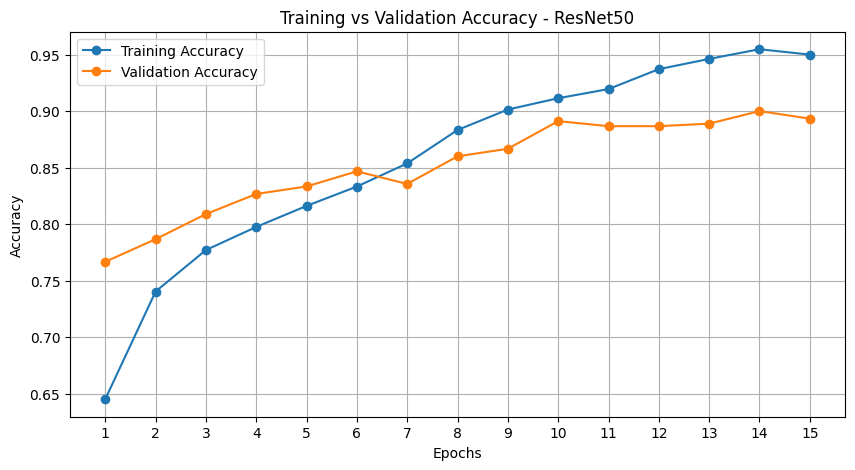

In [23]:
import matplotlib.pyplot as plt

epochs = range(1, 16)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs, resnet_train_acc,
    marker='o', label='Training Accuracy'
)

plt.plot(
    epochs, resnet_val_acc,
    marker='o', label='Validation Accuracy'
)

plt.title("Training vs Validation Accuracy - ResNet50")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()

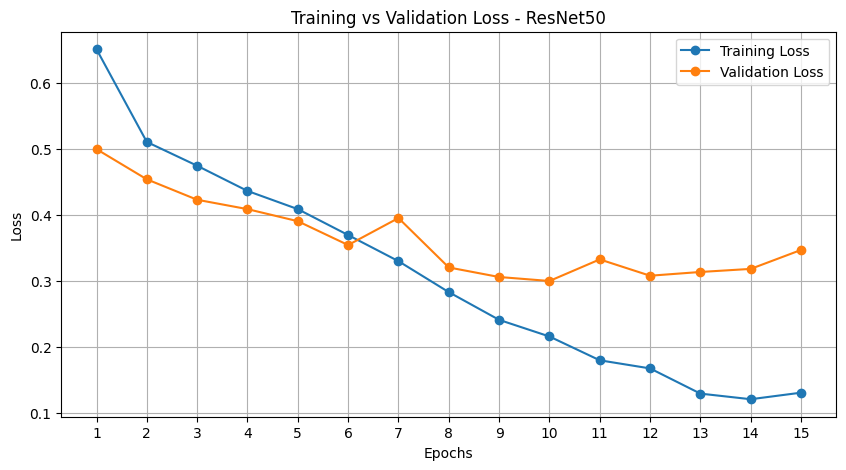

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs, resnet_train_loss,
    marker='o', label='Training Loss'
)

plt.plot(
    epochs, resnet_val_loss,
    marker='o', label='Validation Loss'
)

plt.title("Training vs Validation Loss - ResNet50")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()

In [25]:
from tensorflow.keras.models import load_model

best_resnet_model = load_model(checkpoint_path)

print("Best ResNet50 model loaded successfully!")

Best ResNet50 model loaded successfully!


In [26]:
test_loss, test_accuracy = best_resnet_model.evaluate(
    test_generator,
    verbose=1
)

print("\nResNet50 Test Results")
print("----------------------")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

15/15 ━━━━━━━━━━━━━━━━━━━━ 188s 13s/step - accuracy: 0.8933 - loss: 0.2401

ResNet50 Test Results
----------------------
Test Loss: 0.24007856845855713
Test Accuracy: 0.8933333158493042


In [28]:
import numpy as np

# Generate predictions
predictions = best_resnet_model.predict(test_generator)

# Convert probabilities into class predictions
y_pred = (predictions >= 0.5).astype(int).flatten()

# Get actual labels and convert them into NumPy array
y_true = np.array(test_generator.classes)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

print("\nClass mapping:")
print(test_generator.class_indices)

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step
Actual labels shape: (450,)
Predicted labels shape: (450,)

Class mapping:
{'Down Syndrome': 0, 'Healthy': 1}


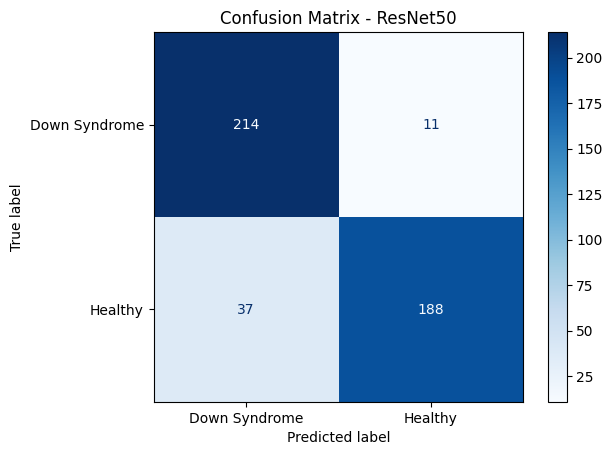

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Down Syndrome", "Healthy"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - ResNet50")
plt.show()

In [30]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Down Syndrome", "Healthy"],
    digits=4
))

               precision    recall  f1-score   support

Down Syndrome     0.8526    0.9511    0.8992       225
      Healthy     0.9447    0.8356    0.8868       225

     accuracy                         0.8933       450
    macro avg     0.8987    0.8933    0.8930       450
 weighted avg     0.8987    0.8933    0.8930       450

